In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, get_scorer, mean_absolute_error, r2_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector

# --- Optuna : optimisation bayésienne des hyperparamètres -----------------------------------
import optuna
from optuna.samplers import TPESampler  # échantillonneur TPE, graine fixée pour la reproductibilité
from optuna.trial import TrialState     # filtrage des essais terminés dans les tableaux de résultats

c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed_vf.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units_vf.csv"

df = pd.read_csv(path_data_processed, sep = ";")
df = df.drop(columns = ['Charpy impact toughness', 'Charpy temperature'])
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5
n_TRIALS = 200 #budget d'essaie pour Optuna qui est identique pour chaque modèle optimisé

mask_TARGETS = (correspondance_between_names_units["Role"] == "Quality indicator")
TARGETS = list(set(correspondance_between_names_units.loc[mask_TARGETS, "Feature"])& set(df.columns))
TARGETS_CAT = ["Charpy conforme"]
TARGETS_NUM = list(set(TARGETS) - set(TARGETS_CAT))
ID_COL = "Weld ID"

COL_NUM = [
    col for col in df.select_dtypes(include="number").columns
    if col not in TARGETS and col != ID_COL
]

COL_CAT = [
    col for col in df.select_dtypes(include="object").columns
    if col not in TARGETS and col != ID_COL
]

C:\Users\andem\AppData\Local\Temp\ipykernel_10936\150412887.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in df.select_dtypes(include="object").columns


## 1. Introduction : prise de connaissance sur nos features et séparation des données en train/test

Avant de commencer la partie sur la prédiction de notre variable, cible nous devons d'abord définir le contexte. 

Le but de notre projet est de pouvoir prédire la qualité de soudure de l'acier. Cependant, nous n'avons pas de feature à proprement en parler sous un nom explicite "Qualité de variable", mais plus 5 indicateurs de qualités de la soudure. Plusieurs procédés sont disponibles, dans ce notebook nous allons essayer de faire une démarche plutôt classique, utilisant au plus les méthodes vu au sein du TD.

Pour ce faire, nous allons choisir de prédire les 5 indicateurs un par un, ceci dit qu'il y aura donc cinq modèles de prédictions différents (de régression ou de classification).

La démarche sera approximativement la suivante : 
1. Imputation des données
2. Réduction des variables
3. Recherche/Benchmark des modèles de prédictions tout en optimisant les paramètres

Etudions d'abord la distribution des features cibles pour guider un peu nos idées.

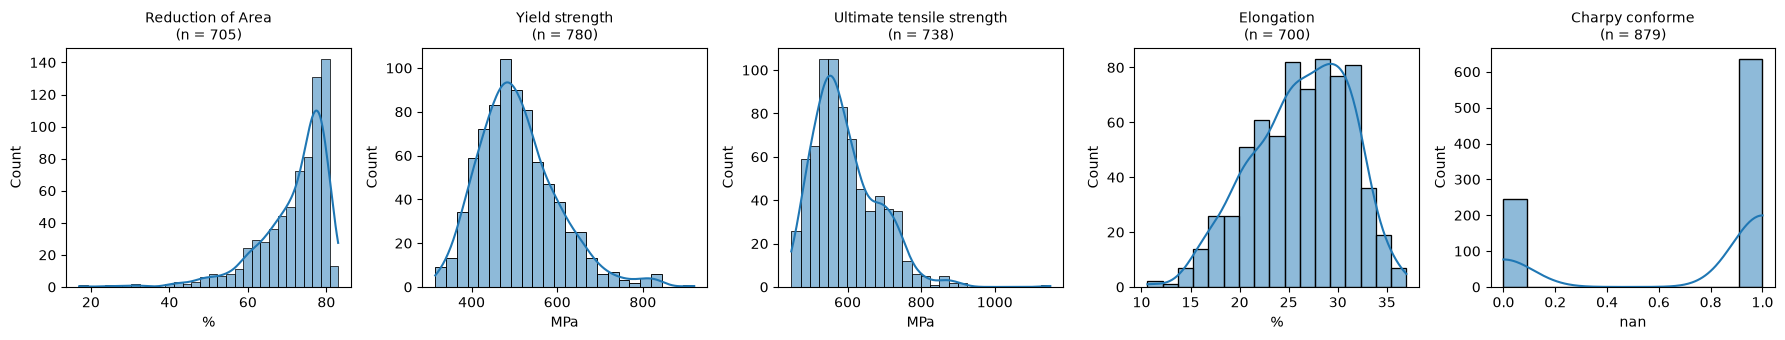

,count,mean,std,min,25%,50%,75%,max
Reduction of Area,705.0,71.8,8.9,17.0,68.0,75.0,78.0,83.0
Yield strength,780.0,508.6,92.9,315.0,443.0,495.0,559.2,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Elongation,700.0,26.3,4.9,10.6,22.8,26.8,30.0,37.0
Charpy conforme,879.0,0.7,0.4,0.0,0.0,1.0,1.0,1.0


In [4]:
# distributions des targets 
fig, axes = plt.subplots(1, len(TARGETS), figsize=(18, 3.5))
for ax, t in zip(axes, TARGETS):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    ax.set_xlabel(correspondance_between_names_units.loc[correspondance_between_names_units['Feature'] == t, 'Unit'].values[0])
plt.tight_layout()
plt.show()

df[TARGETS].describe().T.round(1)

Reduction of Area            705
Yield strength               780
Ultimate tensile strength    738
Elongation                   700
Charpy conforme              879

Lignes avec au moins une cible : 1547
Lignes avec toutes les cibles  : 134
Lignes sans aucune cible       : 105


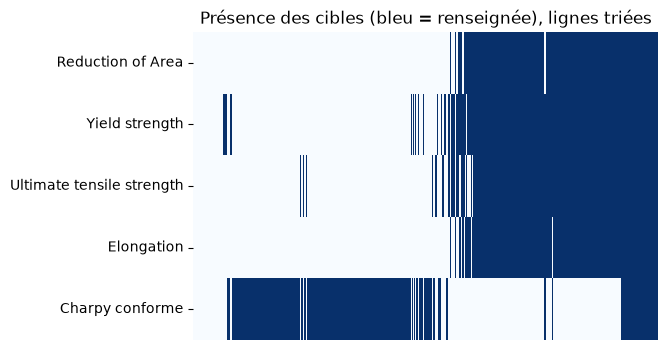

In [5]:
# observons la répartition des instances manquantes par cible
target_counts = df[TARGETS].notna().sum().rename("nb lignes étiquetées")
print(target_counts.to_string())
print(f"\nLignes avec au moins une cible : {df[TARGETS].notna().any(axis=1).sum()}")
print(f"Lignes avec toutes les cibles  : {df[TARGETS].notna().all(axis=1).sum()}")
print(f"Lignes sans aucune cible       : {df[TARGETS].isna().all(axis=1).sum()}")

plt.figure(figsize=(6, 4))
sns.heatmap(df[TARGETS].notna().T.astype(int).loc[:, df[TARGETS].notna().sum(axis=1).sort_values().index],
            cbar=False, cmap="Blues", xticklabels=False)
plt.title("Présence des cibles (bleu = renseignée), lignes triées")
plt.show()

Les éléments remarquables sont les suivants : 
- Seule la feature `Charpy conforme` est catégorielle, donc nous utiliserons une méthode de classification ;
- Le reste des features sont numériques, donc on utilisera une méthode de régression. 

La distribution de chacun des features cibles ne suivent pas tous une distribution gaussienne, même loin d'en être une. Ainsi pour éviter que lors du split train/test on a qu'une proportion de données identiques dans le groupe, on fera de la stratification. Le but serait de pouvoir obtenir une même distribution de variable cible dans les données d'entrainement et de test pour que le modèle apprend "mieux". 

**Dans le cas d'une validation croisée à k-folds, nous allons appliquer à chaque fold la stratifictaion.**

> Par ailleurs, on observe que quand la présence de la valeur de `Charpy conforme` est inversé à celle des autres cibles. Il faut avoir un point de vigilence sur la population d'instance de chaque cible, qu'elle ne sont pas forcément les mêmes. Dans le cadre de cette méthode classique, nous allons devoir exclure les instances où pour la cible étudiée sont vides. 
>
>Si on n'a pas d'instance dans la cible, on n'aura pas de "bonne réponse" pour évaluer notre prédiction. **Mais si on ne souhaite pas supprimer ces instances, il faudra donc passer à de l'apprentissage supervisé (une partie à traité plus tard).**

Chaque instance de notre jeu de données font partie d'un lot de soudure. Quand ils sont issus d'une même référence de soudure, ils sont donc très similaires. Pour éviter d'avoir de la fuite de données, nous allons donc chercher à mettre les instances de la même référence dans le même côté ie. soit dans train, soit dans test. C'est pourquoi ici, pour le split train/test, nous utiliserons la fonction `StratifiedGroupKFold`. Il répartit des groupes entiers dans K paquets, en choisissant la répartition qui rend la distribution de y la plus proche possible dans chaque paquet. Pour ce faire, nous allons juste prendre le premier fold pour notre split train/test. 

In [6]:
# Split des données en stratifiant et en fonction du Weld ID
target = "Yield strength" # essaie sur une cible à la fois
d = df[df[target].notna()].reset_index(drop=True)   # on ne garde que les lignes où la cible existe

# On retire les autres cibles des features (elles seraient une fuite)
X = d.drop(columns=TARGETS+[ID_COL])
y = d[target]
groups = d[ID_COL]

# Discrétisation de la cible en quantiles, uniquement pour stratifier
y_bins = pd.qcut(y, q=5, labels=False)

# 5 folds, soit environ 80/20 ; on prend le premier comme train/test
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y_bins, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Vérifications
print(len(train_idx), len(test_idx))
print(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))   # doit être vide
print(y_train.describe(), y_test.describe())

618 162
set()
count    618.000000
mean     507.855340
std       93.567354
min      329.000000
25%      443.000000
50%      493.000000
75%      553.825000
max      920.000000
Name: Yield strength, dtype: float64 count    162.000000
mean     511.234568
std       90.371252
min      315.000000
25%      444.250000
50%      505.500000
75%      570.750000
max      784.000000
Name: Yield strength, dtype: float64


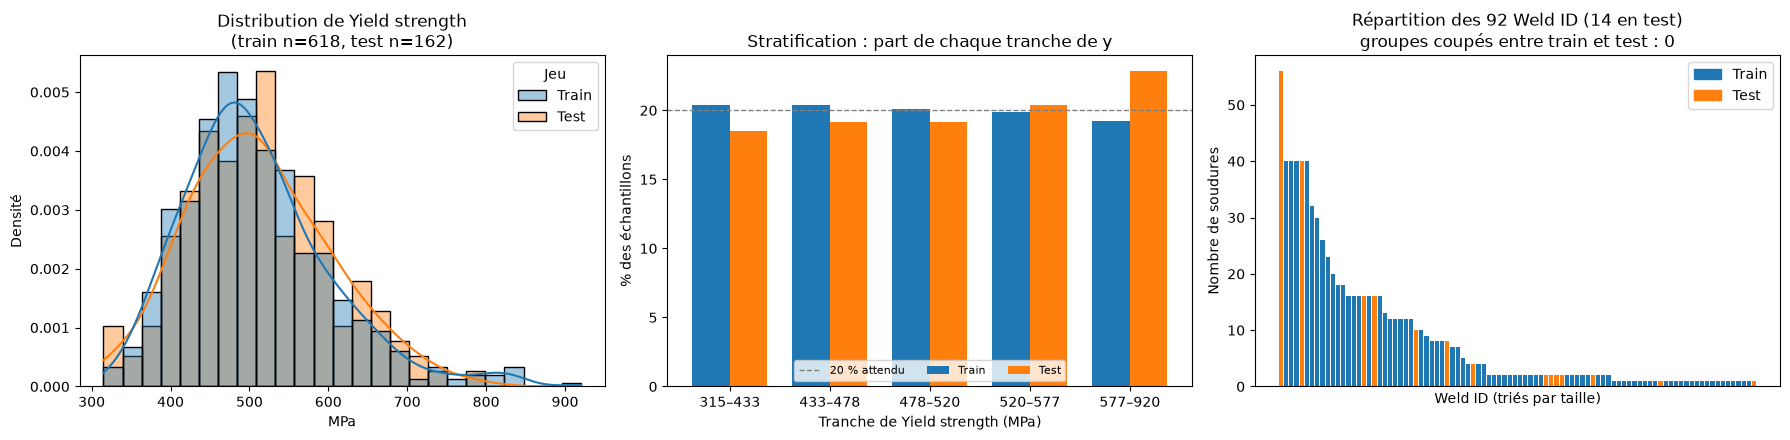

In [7]:
# Étiquette Train/Test pour chaque ligne de d
split = pd.Series("Train", index=d.index, name="Jeu")
split.iloc[test_idx] = "Test"
palette = {"Train": "#1f77b4", "Test": "#ff7f0e"}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Distribution de la cible (densité, pour comparer malgré les tailles différentes)
ax = axes[0]
sns.histplot(x=y, hue=split, stat="density", common_norm=False, kde=True,
             bins=25, palette=palette, alpha=0.4, ax=ax)
ax.set_title(f"Distribution de {target}\n(train n={len(y_train)}, test n={len(y_test)})")
ax.set_xlabel("MPa"); ax.set_ylabel("Densité")

# 2) Proportion de chaque tranche de quantile dans train et test
ax = axes[1]
props = (pd.crosstab(y_bins, split, normalize="columns") * 100)[["Train", "Test"]]
edges = pd.qcut(y, q=5, retbins=True)[1]
props.index = [f"{edges[i]:.0f}–{edges[i+1]:.0f}" for i in props.index]
props.plot.bar(ax=ax, color=[palette["Train"], palette["Test"]], rot=0, width=0.75)
ax.axhline(20, ls="--", c="grey", lw=1, label="20 % attendu")
ax.set_title("Stratification : part de chaque tranche de y")
ax.set_xlabel("Tranche de Yield strength (MPa)"); ax.set_ylabel("% des échantillons")
ax.legend(loc="lower center", ncol=3, fontsize=8)

# 3) Groupes : chaque barre = un Weld ID, colorée selon le côté où il est tombé
ax = axes[2]
g = (pd.DataFrame({"Weld ID": groups, "split": split})
       .groupby("Weld ID").agg(n=("split", "size"), split=("split", "first"))
       .sort_values("n", ascending=False))
n_split_groups = (pd.crosstab(groups, split) > 0).sum(axis=1).gt(1).sum()
ax.bar(range(len(g)), g["n"], color=g["split"].map(palette), width=0.8)
ax.set_title(f"Répartition des {len(g)} Weld ID ({(g['split']=='Test').sum()} en test)\n"
             f"groupes coupés entre train et test : {n_split_groups}")
ax.set_xlabel("Weld ID (triés par taille)"); ax.set_ylabel("Nombre de soudures")
ax.set_xticks([])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=list(palette.keys()))

plt.tight_layout()
plt.show()

Dans les trois graphiques, on voit bien les points suivants :
- la répartition des instances dans le train et le test est très proche ; 
- pour chaque tranche de quantile, on a bien une répartition d'environ 20% dans le train et dans le test (car on a posé `q=5`) ;
- chaque barre indique une référence de soudure, la plus barre est dans le train. Cela peut potentiellement influencer notre prédiction, c'est pourquoi nous pouvons à la fin utiliser une validation croisée pour avoir une mesure d'erreur plus précise.

A partir de là, tous les données de test seront oubliés, on les sollicitera que lorsqu'on évaluera notre modèle.

## 2. Fixation de la méthode d'imputation

In [8]:
# 1) On coupe X_train en deux : une partie pour entraîner, une partie pour valider
tr_idx, val_idx = next(sgkf.split(X_train, y_bins.iloc[train_idx], groups.iloc[train_idx]))
X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

# 2) Les méthodes d'imputation à comparer
num_imputers = {
    "mean":      SimpleImputer(strategy="mean"),
    "median":    SimpleImputer(strategy="median"),
    "zero":      SimpleImputer(strategy="constant", fill_value=0),
    "knn":       make_pipeline(StandardScaler(), KNNImputer(n_neighbors=5)),
    "iterative": IterativeImputer(max_iter=10, random_state=RANDOM_STATE),
}
cat_imputers = {
    "most_frequent": SimpleImputer(strategy="most_frequent"),
    "missing":       SimpleImputer(strategy="constant", fill_value="missing"),
}

# 3) Ce qu'Optuna évalue : une combinaison -> un RMSE sur la validation
def objective(trial):
    num = trial.suggest_categorical("num_imputer", list(num_imputers))
    cat = trial.suggest_categorical("cat_imputer", list(cat_imputers))

    preprocess = ColumnTransformer([
        ("num", clone(num_imputers[num]), COL_NUM),
        ("cat", make_pipeline(clone(cat_imputers[cat]),
                              OneHotEncoder(handle_unknown="ignore")), COL_CAT),
    ])
    model = make_pipeline(preprocess,
                          RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))

    model.fit(X_tr, y_tr)                                        # apprend sur la partie entraînement
    return root_mean_squared_error(y_val, model.predict(X_val))  # note sur la validation

# 4) On teste toutes les combinaisons (5 x 2 = 10)
grid = {"num_imputer": list(num_imputers), "cat_imputer": list(cat_imputers)}
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.GridSampler(grid))
study.optimize(objective, n_trials=10)

print(study.trials_dataframe()[["params_num_imputer", "params_cat_imputer", "value"]]
      .sort_values("value"))
print("Meilleure combinaison :", study.best_params)

[I 2026-10-05 02:12:20,416] A new study created in memory with name: no-name-bc09ac5e-4dd5-429a-8f28-46fa696402c5


[I 2026-10-05 02:12:22,388] Trial 0 finished with value: 80.43482412635294 and parameters: {'num_imputer': 'zero', 'cat_imputer': 'most_frequent'}. Best is trial 0 with value: 80.43482412635294.
[I 2026-10-05 02:12:24,595] Trial 1 finished with value: 82.80700307399755 and parameters: {'num_imputer': 'knn', 'cat_imputer': 'missing'}. Best is trial 0 with value: 80.43482412635294.
c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
[I 2026-10-05 02:12:27,663] Trial 2 finished with value: 82.81805128974898 and parameters: {'num_imputer': 'iterative', 'cat_imputer': 'most_frequent'}. Best is trial 0 with value: 80.43482412635294.
c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
[I 2026-10-05 02:12:31,587] Trial 3

  params_num_imputer params_cat_imputer      value
8               mean      most_frequent  74.482157
9               mean            missing  74.567202
0               zero      most_frequent  80.434824
4             median      most_frequent  80.679631
5             median            missing  80.967830
6               zero            missing  81.603816
3          iterative            missing  81.861386
1                knn            missing  82.807003
2          iterative      most_frequent  82.818051
7                knn      most_frequent  83.083591
Meilleure combinaison : {'num_imputer': 'mean', 'cat_imputer': 'most_frequent'}


Ici, la combinaison de méthode d'imputation avec une RMSE la plus basse possible sur la validation est le meilleur choix. Par exemple pour le cas de la cible `Yield strenght`, nous choisissons *{'num_imputer': 'mean', 'cat_imputer': 'most_frequent'}*, avec une RMSE de validation à 74,12 MPa et la moyenne pour cette cible est de 508 MPa. Alors pour chaque soudure on se trompe de 74 MPa environ, soit environ 15% d'erreur.

## 3. Fixation de la méthode de réduction de dimention

La réduction de dimension est un terme assez large, nous pouvons trouver pas mal de méthode comme la PCA, les méthodes stepwize ou le filtre par corrélation. Pour les méthodes stepwize, le temps d'exécution va être très long, sachant qu'on a quand même 5 targets différents à étudier. Pour une méthode plus rapide, et conserver l'interprétabilité des résultats (pas le cas pour l'ACP) nous optons pour le filtre par corrélation entre les features.

In [9]:
# ------------------------------------------------------------------
# 1) Imputation retenue, apprise sur X_tr uniquement
# ------------------------------------------------------------------
best_imputation = study.best_params
prep = ColumnTransformer([
    ("num", clone(num_imputers[best_imputation["num_imputer"]]), COL_NUM),
    ("cat", make_pipeline(clone(cat_imputers[best_imputation["cat_imputer"]]),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), COL_CAT),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_tr_imp = prep.fit_transform(X_tr)   # apprend sur X_tr
X_val_imp = prep.transform(X_val)     # applique à X_val


# ------------------------------------------------------------------
# 2) Filtre par corrélation : renvoie les colonnes à garder
# ------------------------------------------------------------------
def drop_correlated(X, threshold):
    corr = X.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))  # chaque paire une seule fois
    to_drop = [c for c in upper.columns if (upper[c] > threshold).any()]
    return [c for c in X.columns if c not in to_drop]


# ------------------------------------------------------------------
# 3) Recherche du meilleur seuil avec Optuna
# ------------------------------------------------------------------
def select_features(X_tr, y_tr, X_val, y_val, model, scoring):
    scorer = get_scorer(scoring)
    grid = {"corr_threshold": [1.0, 0.95, 0.90, 0.85, 0.80, 0.70]}   # 1.0 = pas de filtre

    def objective(trial):
        threshold = trial.suggest_categorical("corr_threshold", grid["corr_threshold"])
        cols = drop_correlated(X_tr, threshold)            # appris sur X_tr uniquement
        m = clone(model).fit(X_tr[cols], y_tr)
        trial.set_user_attr("n_features", len(cols))
        trial.set_user_attr("features", cols)
        return scorer(m, X_val[cols], y_val)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.GridSampler(grid))
    study.optimize(objective, n_trials=len(grid["corr_threshold"]))
    return study


# ------------------------------------------------------------------
# 4) Lancement pour Yield strength
# ------------------------------------------------------------------
study_red = select_features(
    X_tr_imp, y_tr, X_val_imp, y_val,
    model=RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    scoring="neg_root_mean_squared_error",
)

res = (study_red.trials_dataframe()
       [["params_corr_threshold", "user_attrs_n_features", "value"]]
       .sort_values("value", ascending=False)
       .reset_index(drop=True))
res["value"] = res["value"].abs()   # RMSE en MPa (le scorer le renvoie en négatif)
print(res.round(2).to_string())

best = study_red.best_trial
print("\nMeilleur seuil :", best.params["corr_threshold"])
removed = [c for c in X_tr_imp.columns if c not in best.user_attrs["features"]]
print("Variables supprimées :", removed)

   params_corr_threshold  user_attrs_n_features  value
0                   0.85                     32  74.13
1                   0.90                     34  74.17
2                   0.95                     34  74.17
3                   1.00                     35  74.48
4                   0.80                     28  75.43
5                   0.70                     27  78.63

Meilleur seuil : 0.85
Variables supprimées : ['Heat input', 'AC or DC_DC', 'Type of weld_TSA']


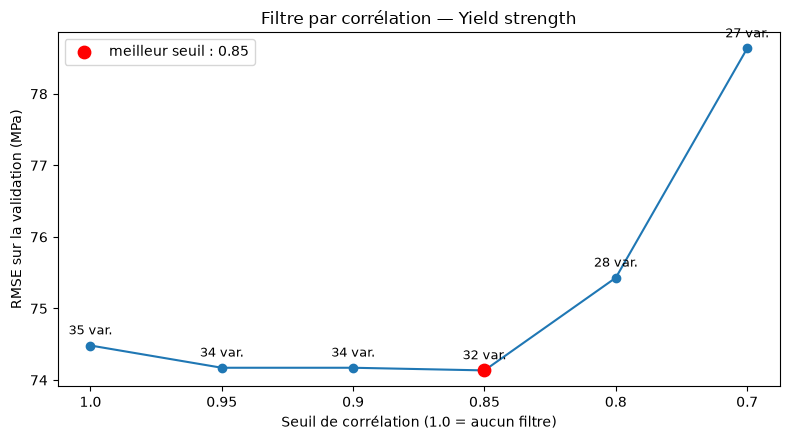

In [10]:
plot_df = res.sort_values("params_corr_threshold", ascending=False)   # 1.0 (aucun filtre) à gauche
x = plot_df["params_corr_threshold"].astype(str)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, plot_df["value"], marker="o", color="#1f77b4")

# nombre de variables gardées au-dessus de chaque point
for xi, v, n in zip(x, plot_df["value"], plot_df["user_attrs_n_features"]):
    ax.annotate(f"{n} var.", (xi, v), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)

# point du meilleur seuil en rouge
best_t = str(study_red.best_params["corr_threshold"])
best_v = plot_df.loc[x == best_t, "value"].iloc[0]
ax.scatter(best_t, best_v, color="red", s=80, zorder=3, label=f"meilleur seuil : {best_t}")

ax.set_xlabel("Seuil de corrélation (1.0 = aucun filtre)")
ax.set_ylabel("RMSE sur la validation (MPa)")
ax.set_title(f"Filtre par corrélation — {target}")
ax.legend()
plt.tight_layout()
plt.show()

On chercher juste à savoir quelle seuil de corrélation à choisir, par l'optimisation Optuna on déduit qu'un seuil de 0,85 donne un bon RMSE sur les données de validations (obtenu sur la cible `Yield strenght`).

## 4. Sélection de modèle

Maintenant, nous allons attaquer à la partie sérieuse du projet "la sélection de modèle". Ici en principe nous avons plusieurs candidats de modèle, valable en régression ou en classification : 
- la régression linéaire / la classification binaire ;
- l'arbre de décision ;
- le Random Forest (basée sur la méthode de bagging) ;
- XGBoost (basée sur la méthode de boosting).

Pour cela, nous utiliserons Optuna pour faire le choix du modèle ou même des hyperparamètres.

Colonnes supprimées : ['Heat input']


Best trial: 16. Best value: 85.1644: 100%|██████████| 50/50 [00:11<00:00,  4.36it/s]


Ridge : RMSE CV = 85.2 MPa | {'alpha': 846.6189702830851}


Best trial: 44. Best value: 88.6357: 100%|██████████| 50/50 [00:11<00:00,  4.42it/s]


Arbre : RMSE CV = 88.6 MPa | {'max_depth': 4, 'min_samples_leaf': 13}


Best trial: 35. Best value: 72.192: 100%|██████████| 50/50 [04:08<00:00,  4.98s/it] 


Random Forest : RMSE CV = 72.2 MPa | {'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.3141382170424881}


Best trial: 47. Best value: 67.4096: 100%|██████████| 50/50 [07:28<00:00,  8.98s/it]


XGBoost : RMSE CV = 67.4 MPa | {'n_estimators': 514, 'learning_rate': 0.14078635310280915, 'max_depth': 3, 'subsample': 0.7269839096369998, 'colsample_bytree': 0.607909164045277, 'min_child_weight': 3}
                     moyenne  ecart_type     SE  pire_fold
XGBoost                67.41       12.77   5.71      82.04
Random Forest          72.19       13.41   6.00      88.94
Ridge                  85.16       11.90   5.32      98.88
Arbre                  88.64       11.10   4.97     103.65
Baseline (moyenne)     92.84       11.13   4.98     108.02
Régression linéaire   127.92       76.93  34.41     264.77


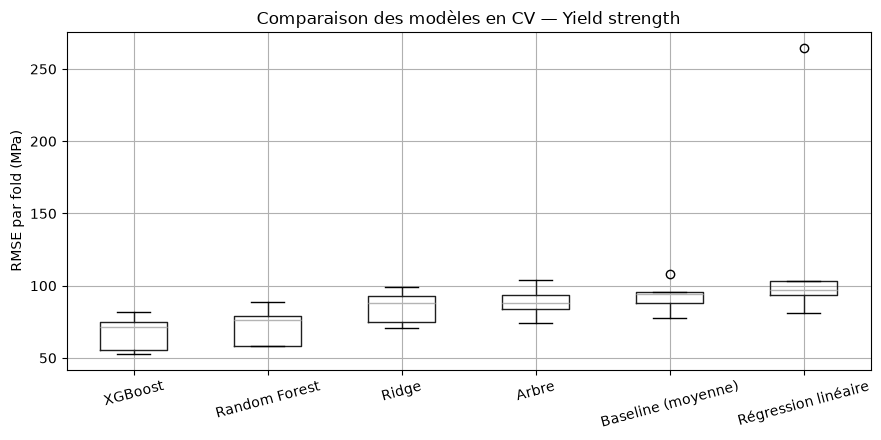

Meilleur modèle : XGBoost | seuil 1-SE = 73.1 MPa

                     moyenne     SE  complexite  ecart_moyen  SE_ecart  indisc_1SE  indisc_apparie
Régression linéaire   127.92  34.41           1        60.51     33.21       False            True
Ridge                  85.16   5.32           2        17.75      3.11       False           False
Arbre                  88.64   4.97           3        21.23      3.94       False           False
Random Forest          72.19   6.00           4         4.78      0.74        True           False
XGBoost                67.41   5.71           5         0.00      0.00        True            True

Modèle retenu (le plus simple parmi les indiscernables) : Random Forest
Modèle final : Random Forest {'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.3141382170424881}
RMSE CV   = 72.2 ± 6.0 MPa (SE)
RMSE test = 82.5 MPa | MAE = 63.4 | R² = 0.161


In [11]:
# ==================================================================
# 0) Données : on applique les choix des étapes précédentes
# ==================================================================
# Colonnes d'origine supprimées par le filtre de corrélation
# (les colonnes one-hot éventuellement supprimées sont ignorées : elles sont redondantes entre elles)
cols_gardees = study_red.best_trial.user_attrs["features"]
cols_supprimees = [c for c in X_train.columns if c in X_tr_imp.columns and c not in cols_gardees]
print("Colonnes supprimées :", cols_supprimees)

X_train_red = X_train.drop(columns=cols_supprimees)
X_test_red = X_test.drop(columns=cols_supprimees)
COL_NUM_RED = [c for c in COL_NUM if c not in cols_supprimees]
COL_CAT_RED = [c for c in COL_CAT if c not in cols_supprimees]

# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
y_bins_train = y_bins.iloc[train_idx]
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
             .split(X_train_red, y_bins_train, groups_train))


# ==================================================================
# 1) Prétraitement (imputation retenue) : appris dans chaque fold
# ==================================================================
def construire_prep():
    return ColumnTransformer([
        ("num", clone(num_imputers[best_imputation["num_imputer"]]), COL_NUM_RED),
        ("cat", make_pipeline(clone(cat_imputers[best_imputation["cat_imputer"]]),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), COL_CAT_RED),
    ])


# ==================================================================
# 2) Fonction d'évaluation unique
# ==================================================================
def metriques(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


def evaluer_cv(modele, X, y, folds):
    scores = []
    for idx_tr, idx_va in folds:
        m = clone(modele)                                   # modèle neuf à chaque fold
        m.fit(X.iloc[idx_tr], y.iloc[idx_tr])
        scores.append(metriques(y.iloc[idx_va], m.predict(X.iloc[idx_va])))
    return pd.DataFrame(scores)                             # une ligne par fold


def resumer(scores, metrique="RMSE"):
    s = scores[metrique]
    return {"moyenne": s.mean(),
            "ecart_type": s.std(),
            "SE": s.std() / np.sqrt(len(s)),
            "pire_fold": s.max()}                           # pour le RMSE, le pire = le plus grand


registre = {}   # nom du modèle -> DataFrame des scores par fold


# ==================================================================
# 3) Les modèles et leurs hyperparamètres à régler
#    (chaque fonction reçoit un trial Optuna et renvoie un modèle)
# ==================================================================
def ridge(trial):
    return make_pipeline(StandardScaler(),                  # standardisation obligatoire
                         Ridge(alpha=trial.suggest_float("alpha", 1e-3, 1e3, log=True)))


def arbre(trial):
    return DecisionTreeRegressor(
        max_depth=trial.suggest_int("max_depth", 2, 15),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
        random_state=RANDOM_STATE)


def random_forest(trial):
    return RandomForestRegressor(
        n_estimators=300,                                   # fixé : pas critique
        max_depth=trial.suggest_int("max_depth", 3, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        max_features=trial.suggest_float("max_features", 0.3, 1.0),
        n_jobs=-1, random_state=RANDOM_STATE)


def xgboost(trial):
    return XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 800),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        n_jobs=-1, random_state=RANDOM_STATE)


# ==================================================================
# 4) Réglage de chaque modèle avec Optuna (même budget pour tous)
# ==================================================================
def optimiser(nom, construire_modele, n_trials=50):
    def objective(trial):
        pipe = make_pipeline(construire_prep(), construire_modele(trial))
        return evaluer_cv(pipe, X_train_red, y_train, folds)["RMSE"].mean()

    study = optuna.create_study(direction="minimize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    # On reconstruit le meilleur modèle et on enregistre ses scores par fold
    meilleur = make_pipeline(construire_prep(),
                             construire_modele(optuna.trial.FixedTrial(study.best_params)))
    registre[nom] = evaluer_cv(meilleur, X_train_red, y_train, folds)
    print(f"{nom} : RMSE CV = {study.best_value:.1f} MPa | {study.best_params}")
    return meilleur, study.best_params


optuna.logging.set_verbosity(optuna.logging.WARNING)

# Référence naïve : prédit toujours la moyenne (rien à régler)
registre["Baseline (moyenne)"] = evaluer_cv(make_pipeline(construire_prep(), DummyRegressor()),
                                            X_train_red, y_train, folds)

modeles, params = {}, {}

# Régression linéaire classique : rien à régler, évaluation directe
lin = make_pipeline(construire_prep(), StandardScaler(), LinearRegression())
registre["Régression linéaire"] = evaluer_cv(lin, X_train_red, y_train, folds)
modeles["Régression linéaire"], params["Régression linéaire"] = lin, {}

# Modèles avec hyperparamètres réglés par Optuna
for nom, fn in [("Ridge", ridge), ("Arbre", arbre),
                ("Random Forest", random_forest), ("XGBoost", xgboost)]:
    modeles[nom], params[nom] = optimiser(nom, fn, n_trials=50)


# ==================================================================
# 5) Comparaison des modèles réglés
# ==================================================================
tableau = (pd.DataFrame({nom: resumer(s) for nom, s in registre.items()}).T
           .sort_values("moyenne"))
print(tableau.round(2))

# Boxplot des RMSE par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s["RMSE"] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel("RMSE par fold (MPa)")
ax.set_title(f"Comparaison des modèles en CV — {target}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ==================================================================
# 5 bis) Modèles indiscernables du meilleur et choix du plus simple
# ==================================================================
COMPLEXITE = {"Régression linéaire": 1, "Ridge": 2, "Arbre": 3,
              "Random Forest": 4, "XGBoost": 5}

noms = [n for n in COMPLEXITE if n in tableau.index]
cand = tableau.loc[noms, ["moyenne", "SE"]].copy()
cand["complexite"] = pd.Series(COMPLEXITE)

# Meilleur modèle et seuil 1-SE
nom_best = cand["moyenne"].idxmin()
seuil = cand.loc[nom_best, "moyenne"] + cand.loc[nom_best, "SE"]

# Comparaison appariée : écart fold par fold avec le meilleur (mêmes folds)
rmse_best = registre[nom_best]["RMSE"]
for nom in noms:
    ecarts = registre[nom]["RMSE"] - rmse_best
    cand.loc[nom, "ecart_moyen"] = ecarts.mean()
    cand.loc[nom, "SE_ecart"] = ecarts.std() / np.sqrt(len(ecarts))

cand["indisc_1SE"] = cand["moyenne"] <= seuil
cand["indisc_apparie"] = cand["ecart_moyen"] <= 2 * cand["SE_ecart"]

cand = cand.sort_values("complexite")
print(f"Meilleur modèle : {nom_best} | seuil 1-SE = {seuil:.1f} MPa\n")
print(cand.round(2).to_string())

# Choix : le plus simple parmi les indiscernables (règle 1-SE)
nom_final = cand[cand["indisc_1SE"]].index[0]
print(f"\nModèle retenu (le plus simple parmi les indiscernables) : {nom_final}")

# ==================================================================
# 6) Évaluation finale UNE SEULE FOIS sur le test
# ==================================================================
modele_final = modeles[nom_final]
modele_final.fit(X_train_red, y_train)                        # réentraîné sur tout X_train
score_test = metriques(y_test, modele_final.predict(X_test_red))

print(f"Modèle final : {nom_final} {params[nom_final]}")
print(f"RMSE CV   = {tableau.loc[nom_final, 'moyenne']:.1f} ± {tableau.loc[nom_final, 'SE']:.1f} MPa (SE)")
print(f"RMSE test = {score_test['RMSE']:.1f} MPa | MAE = {score_test['MAE']:.1f} | R² = {score_test['R2']:.3f}")

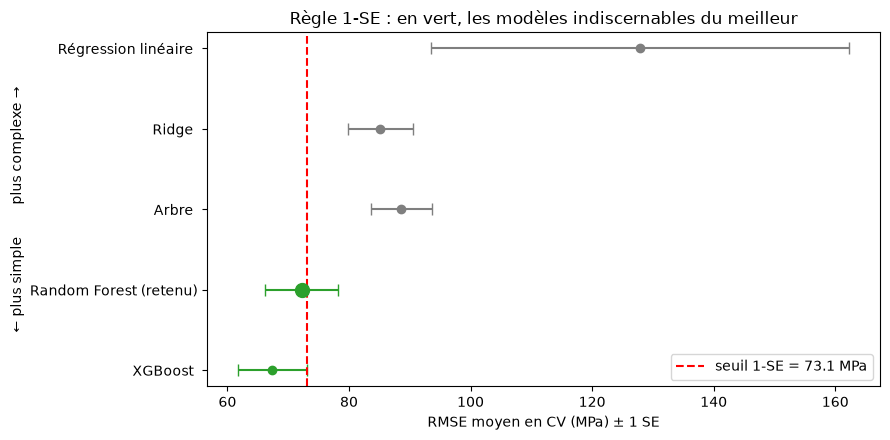

In [12]:
# ------------------------------------------------------------------
# Graphe : modèles rangés par complexité, indiscernables en vert
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
ypos = np.arange(len(cand))
couleurs = ["#2ca02c" if ok else "#7f7f7f" for ok in cand["indisc_1SE"]]
for y, (nom, row), c in zip(ypos, cand.iterrows(), couleurs):
    ax.errorbar(row["moyenne"], y, xerr=row["SE"], fmt="o", capsize=4, color=c,
                markersize=10 if nom == nom_final else 6)
ax.axvline(seuil, ls="--", c="red", label=f"seuil 1-SE = {seuil:.1f} MPa")
ax.set_yticks(ypos, [f"{n} {'(retenu)' if n == nom_final else ''}" for n in cand.index])
ax.invert_yaxis()
ax.set_xlabel("RMSE moyen en CV (MPa) ± 1 SE")
ax.set_ylabel("← plus simple        plus complexe →")
ax.set_title("Règle 1-SE : en vert, les modèles indiscernables du meilleur")
ax.legend()
plt.tight_layout()
plt.show()

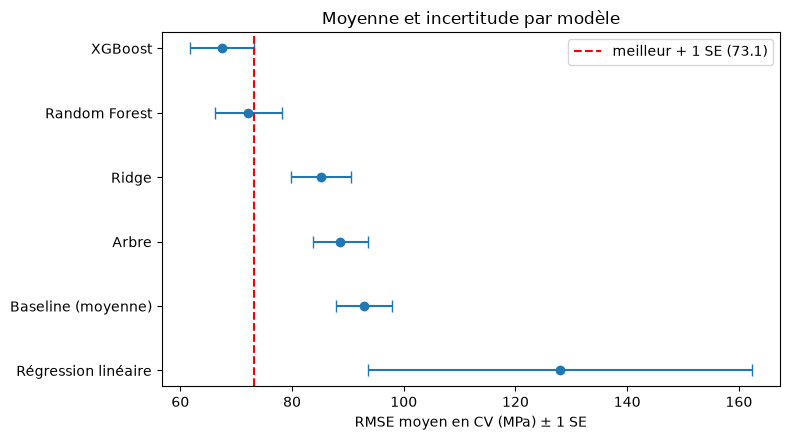

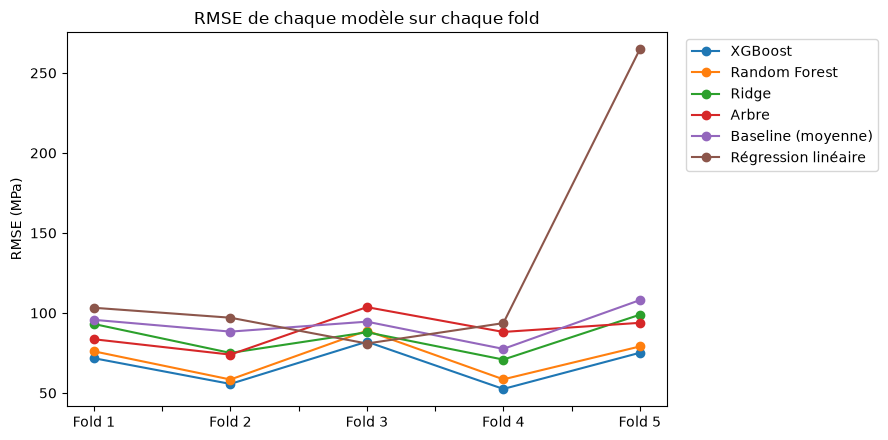

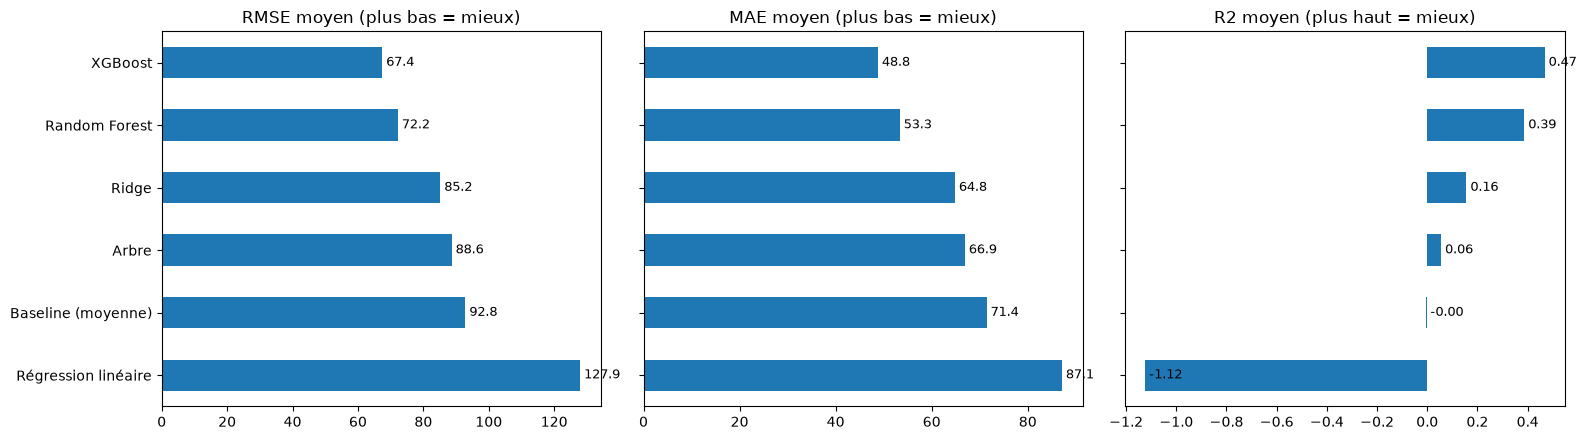

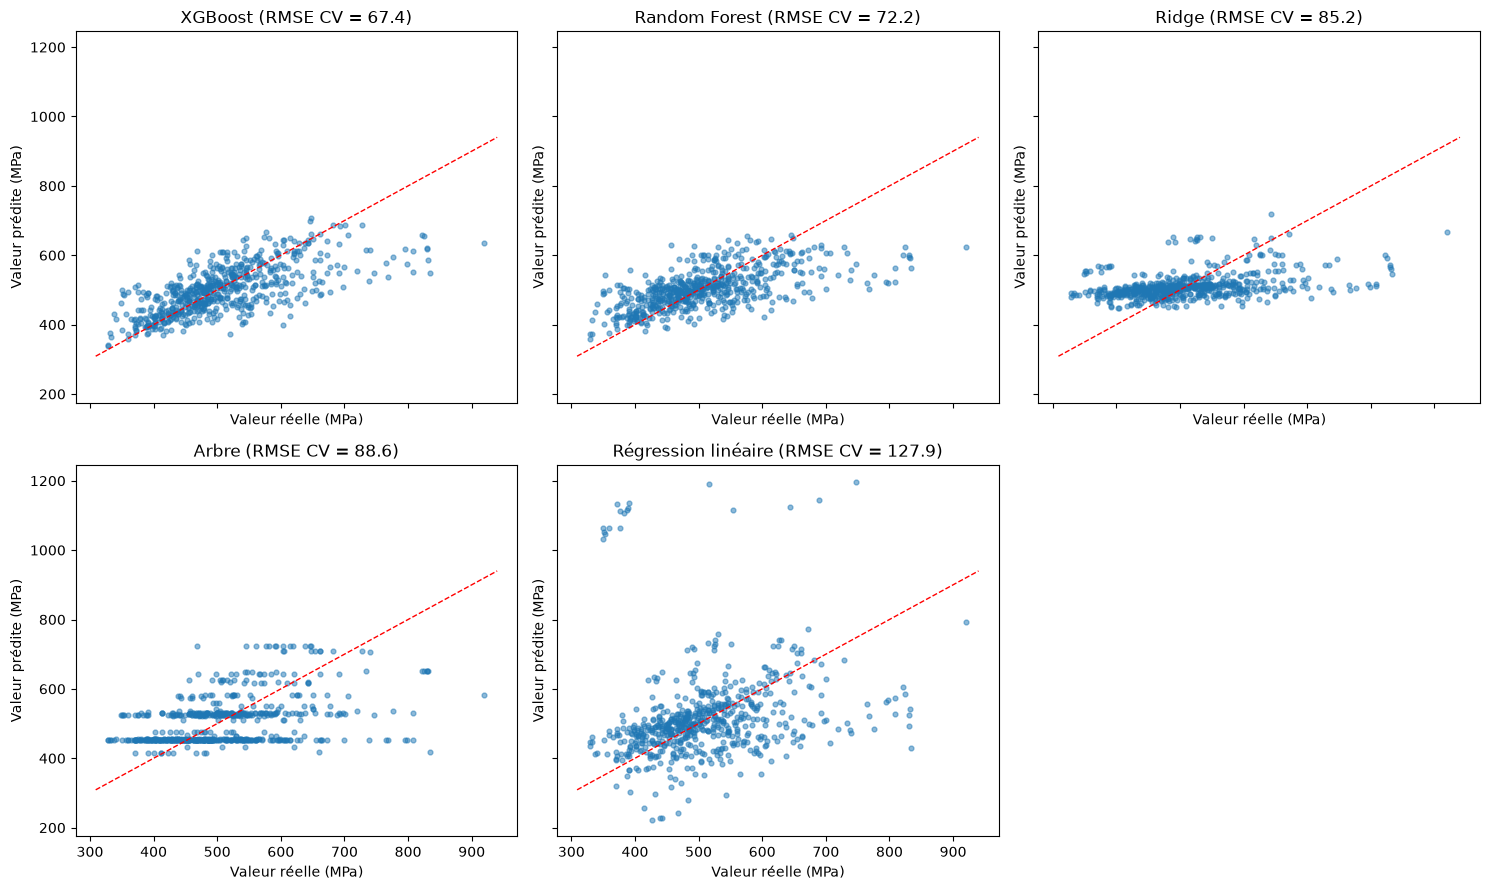

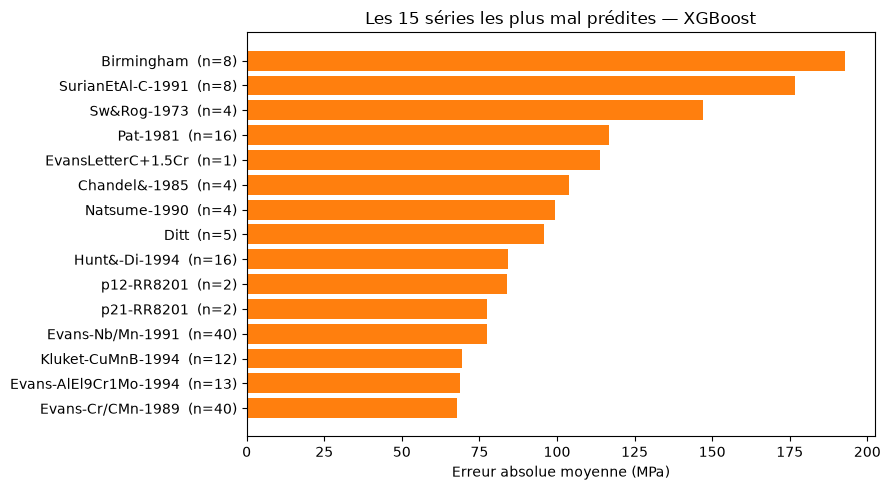

In [13]:
from sklearn.model_selection import cross_val_predict

t = tableau.sort_values("moyenne")
noms_modeles = [n for n in t.index if n in modeles]   # sans la baseline

# ------------------------------------------------------------------
# A) RMSE moyen ± SE, avec le seuil de la règle 1-SE
# ------------------------------------------------------------------
best = t.loc[noms_modeles[0]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(t))
ax.errorbar(t["moyenne"], ypos, xerr=t["SE"], fmt="o", capsize=4, color="#1f77b4")
ax.axvline(best["moyenne"] + best["SE"], ls="--", c="red",
           label=f"meilleur + 1 SE ({best['moyenne'] + best['SE']:.1f})")
ax.set_yticks(ypos, t.index)
ax.invert_yaxis()
ax.set_xlabel("RMSE moyen en CV (MPa) ± 1 SE")
ax.set_title("Moyenne et incertitude par modèle")
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# B) RMSE fold par fold : le classement est-il le même partout ?
# ------------------------------------------------------------------
fold_rmse = pd.DataFrame({nom: s["RMSE"] for nom, s in registre.items()})[t.index]
fold_rmse.index = [f"Fold {i + 1}" for i in range(len(fold_rmse))]

fig, ax = plt.subplots(figsize=(9, 4.5))
fold_rmse.plot(marker="o", ax=ax)
ax.set_ylabel("RMSE (MPa)")
ax.set_title("RMSE de chaque modèle sur chaque fold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# C) Les trois métriques côte à côte
# ------------------------------------------------------------------
moyennes = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (m, sens) in zip(axes, [("RMSE", "plus bas = mieux"),
                                ("MAE", "plus bas = mieux"),
                                ("R2", "plus haut = mieux")]):
    moyennes[m].plot.barh(ax=ax, color="#1f77b4")
    for i, v in enumerate(moyennes[m]):
        ax.text(v, i, f" {v:.2f}" if m == "R2" else f" {v:.1f}", va="center", fontsize=9)
    ax.set_title(f"{m} moyen ({sens})")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# D) Prédictions hors-fold vs valeurs réelles, pour chaque modèle
#    (chaque soudure est prédite par le modèle qui ne l'a pas vue)
# ------------------------------------------------------------------
oof = {nom: cross_val_predict(modeles[nom], X_train_red, y_train, cv=folds)
       for nom in noms_modeles}

n = len(noms_modeles)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows),
                         sharex=True, sharey=True)
lims = [y_train.min() - 20, y_train.max() + 20]
for ax, nom in zip(axes.flat, noms_modeles):
    ax.scatter(y_train, oof[nom], s=12, alpha=0.5)
    ax.plot(lims, lims, "r--", lw=1)                       # prédiction parfaite
    ax.set_title(f"{nom} (RMSE CV = {t.loc[nom, 'moyenne']:.1f})")
    ax.set_xlabel("Valeur réelle (MPa)")
    ax.set_ylabel("Valeur prédite (MPa)")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# E) Erreur moyenne par série (Weld ID) pour le meilleur modèle
# ------------------------------------------------------------------
nom_best = noms_modeles[0]
err_groupes = (pd.DataFrame({"groupe": groups_train.values,
                             "erreur_abs": np.abs(oof[nom_best] - y_train.values)})
               .groupby("groupe")["erreur_abs"].agg(["mean", "size"])
               .sort_values("mean", ascending=False)
               .head(15))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(err_groupes.index + "  (n=" + err_groupes["size"].astype(str) + ")",
        err_groupes["mean"], color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Erreur absolue moyenne (MPa)")
ax.set_title(f"Les 15 séries les plus mal prédites — {nom_best}")
plt.tight_layout()
plt.show()

Modèle final : Random Forest
Hyperparamètres : {'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.3141382170424881}

      CV (moyenne des folds)    Test  Baseline sur le test
RMSE                  72.192  82.504                90.155
MAE                   53.334  63.363                71.540
R2                     0.386   0.161                -0.001

RMSE test = 82.5 MPa, intervalle à 95 % : [44.2 ; 103.1] MPa
RMSE CV   = 72.2 ± 6.0 MPa (SE)


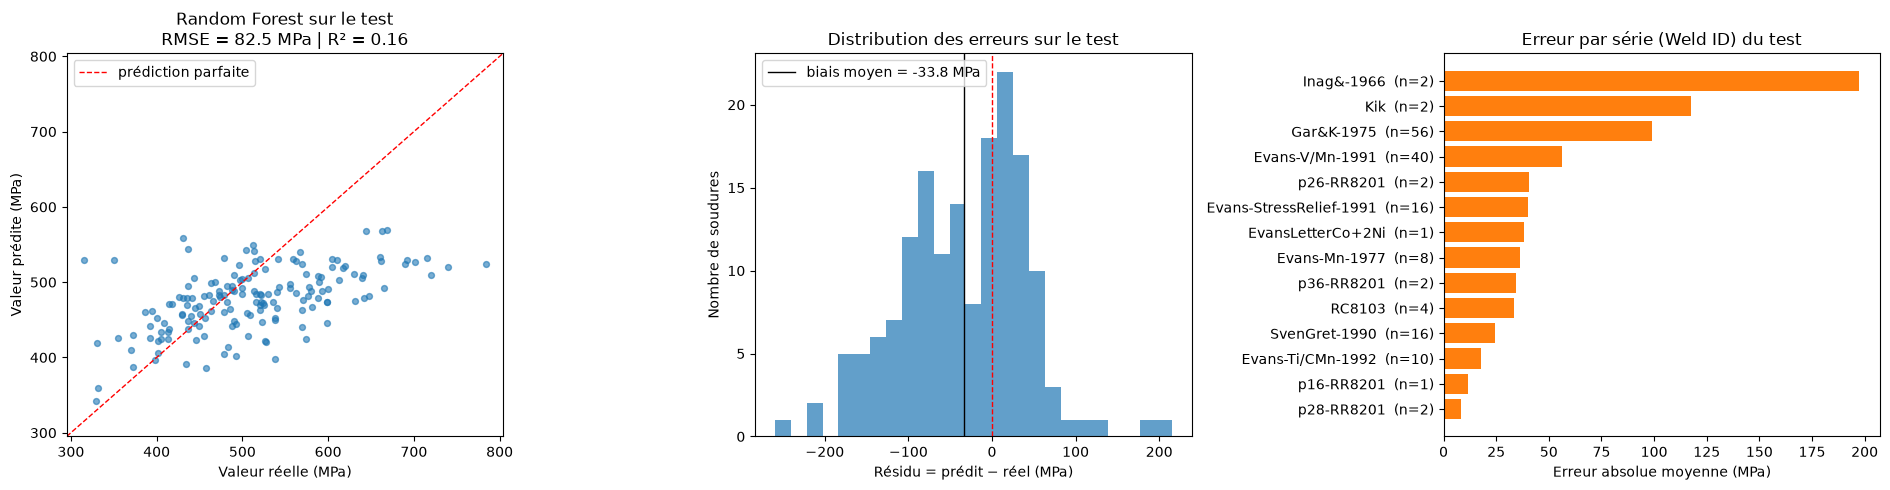

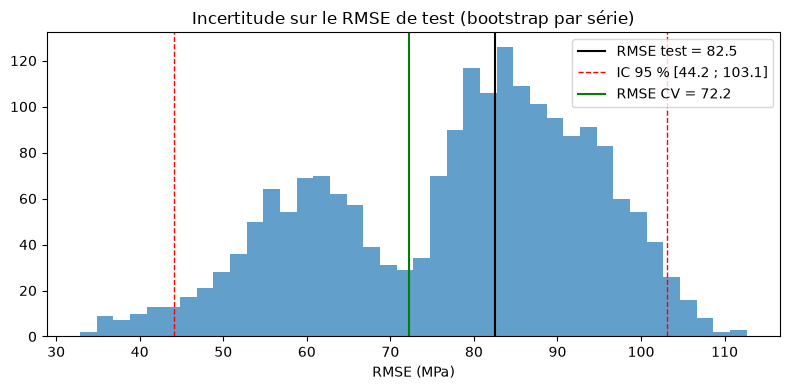

In [14]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
# ==================================================================

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
score_test = metriques(y_test, y_pred_test)

# Référence naïve sur le test (prédit la moyenne du train), pour situer le score
baseline = make_pipeline(construire_prep(), DummyRegressor()).fit(X_train_red, y_train)
score_base = metriques(y_test, baseline.predict(X_test_red))

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (moyenne des folds)": registre[nom_final].mean(),
    "Test": pd.Series(score_test),
    "Baseline sur le test": pd.Series(score_base),
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance du RMSE de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test})
par_groupe = {g: df for g, df in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

rng = np.random.default_rng(RANDOM_STATE)
boot_rmse = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    boot_rmse.append(root_mean_squared_error(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_rmse, [2.5, 97.5])

print(f"\nRMSE test = {score_test['RMSE']:.1f} MPa, "
      f"intervalle à 95 % : [{ic_bas:.1f} ; {ic_haut:.1f}] MPa")
print(f"RMSE CV   = {tableau.loc[nom_final, 'moyenne']:.1f} ± {tableau.loc[nom_final, 'SE']:.1f} MPa (SE)")

# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["residu"] = res_test["predit"] - res_test["reel"]
err_series = (res_test.assign(erreur_abs=res_test["residu"].abs())
              .groupby("groupe")["erreur_abs"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# a) Prédit vs réel
ax = axes[0]
lims = [min(res_test["reel"].min(), res_test["predit"].min()) - 20,
        max(res_test["reel"].max(), res_test["predit"].max()) + 20]
ax.scatter(res_test["reel"], res_test["predit"], s=18, alpha=0.6)
ax.plot(lims, lims, "r--", lw=1, label="prédiction parfaite")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Valeur réelle (MPa)")
ax.set_ylabel("Valeur prédite (MPa)")
ax.set_title(f"{nom_final} sur le test\nRMSE = {score_test['RMSE']:.1f} MPa | R² = {score_test['R2']:.2f}")
ax.legend()

# b) Distribution des résidus
ax = axes[1]
ax.hist(res_test["residu"], bins=25, color="#1f77b4", alpha=0.7)
ax.axvline(0, c="r", ls="--", lw=1)
ax.axvline(res_test["residu"].mean(), c="k", lw=1,
           label=f"biais moyen = {res_test['residu'].mean():.1f} MPa")
ax.set_xlabel("Résidu = prédit − réel (MPa)")
ax.set_ylabel("Nombre de soudures")
ax.set_title("Distribution des erreurs sur le test")
ax.legend()

# c) Erreur par série du test
ax = axes[2]
ax.barh(err_series.index + "  (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"], color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Erreur absolue moyenne (MPa)")
ax.set_title("Erreur par série (Weld ID) du test")

plt.tight_layout()
plt.show()

# d) Distribution bootstrap du RMSE de test
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_rmse, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test["RMSE"], c="k", lw=1.5, label=f"RMSE test = {score_test['RMSE']:.1f}")
ax.axvline(ic_bas, c="r", ls="--", lw=1, label=f"IC 95 % [{ic_bas:.1f} ; {ic_haut:.1f}]")
ax.axvline(ic_haut, c="r", ls="--", lw=1)
ax.axvline(tableau.loc[nom_final, "moyenne"], c="g", lw=1.5,
           label=f"RMSE CV = {tableau.loc[nom_final, 'moyenne']:.1f}")
ax.set_xlabel("RMSE (MPa)")
ax.set_title("Incertitude sur le RMSE de test (bootstrap par série)")
ax.legend()
plt.tight_layout()
plt.show()